In [1]:
%run ./dataManipulation.ipynb

In [2]:
import seaborn as sns
from scipy import stats

from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder

from sklearn.model_selection import StratifiedGroupKFold, GroupShuffleSplit, GridSearchCV
from sklearn.metrics import f1_score, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

2024-03-04 13:57:12.439343: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [3]:
columns = ['clipID', 'Extraversion', 'Agreeableness', 'Conscientiousness', 'Neuroticism', 'Openness', 'Gender']
listOfGenders = np.array(metadata)[:,2]
unique_values, counts = np.unique(listOfGenders, return_counts=True)

## Class Imbalance

,Value,Frequency,Percentage
Male,0,503,78.59375
Female,1,137,21.40625


Text(0.5, 1.0, 'Frequency of Female vs Male classes')

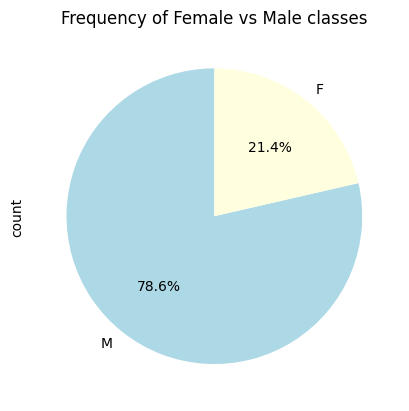

In [4]:
labelencoder=LabelEncoder()
y=to_categorical(labelencoder.fit_transform(listOfGenders))[:,0].astype(int)
# No of men vs no of women

valueCounts = pd.DataFrame(y).value_counts().reset_index()
valueCounts.columns = ['Value', 'Frequency']
valueCounts = valueCounts.rename(index={0: 'Male', 1: 'Female'})
totalClips = valueCounts['Frequency'].sum()
valueCounts['Percentage'] = (valueCounts['Frequency'] / totalClips) * 100
display(Markdown('## Class Imbalance'))
display(valueCounts)


array = np.concatenate((medianScoresPerClip(), listOfGenders.reshape(-1,1)), axis=1)
df = pd.DataFrame(array, columns=columns)
dfMale = df[df.Gender == 'M']
dfFemale = df[df.Gender == 'F']
df = pd.concat([dfMale, dfFemale])
ax = df.Gender.value_counts().plot(kind='pie', autopct='%1.1f%%', startangle=90, colors=['lightblue', 'lightyellow'])
ax.set_title('Frequency of Female vs Male classes')

## PCA

Pricipal component variance: [0.35845079 0.29290806]
Relationship between original features (Big Five) and Principal Components:                         PC1       PC2
Extraversion       0.602524 -0.157927
Agreeableness     -0.371915 -0.584500
Conscientiousness  0.370081 -0.533504
Neuroticism        0.487827  0.439006
Openness           0.351723 -0.395052
Amount of variance per principal component: [0.35845079 0.29290806 0.15350095 0.10301126 0.09212895]


<Figure size 640x480 with 0 Axes>

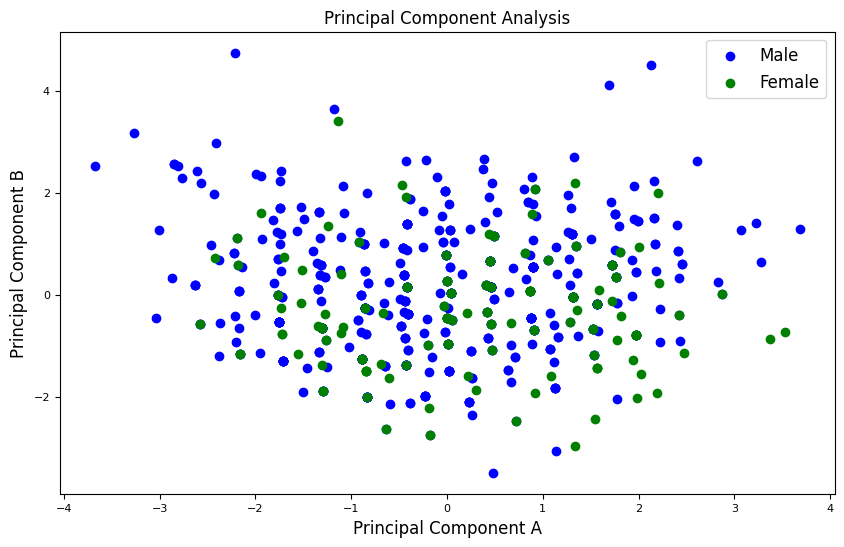

In [5]:
data = medianScoresPerClip()[:,1:]

labels = np.reshape(y, (640,1))
finalData = np.concatenate([data, labels], axis=1)
finalDataset = pd.DataFrame(finalData)
finalDataset.columns = columns[1:]
finalDataset['Gender'].replace(0, 'Male',inplace=True)
finalDataset['Gender'].replace(1, 'Female',inplace=True)

x = finalDataset.loc[:, columns[1:6]].values

# x = finalDataset.loc[:, columns[1:6]].iloc[:, ::-1].values
x = StandardScaler().fit_transform(x)

# featureCols = ['feature'+ str(i) for i in range(x.shape[1])]

normalised = pd.DataFrame(x, columns=bigFive)
# normalised.head()

pca = PCA(n_components=2)
princComp = pca.fit_transform(x)
pcaDf = pd.DataFrame(data = princComp, columns = ['principal component 1', 'principal component 2'])

# VARIANCE OF THE DATASET DEFINED BY EACH COMPONENT OF THE TWO
print('Pricipal component variance: {}'.format(pca.explained_variance_ratio_))

# Relationship between original features (Big Five) and Principal Components
loadings = pd.DataFrame(pca.components_.T, columns=['PC1', 'PC2'], index=bigFive)
print("Relationship between original features (Big Five) and Principal Components:", loadings)

# Two components result to 65% of variance while we need 4 to get 90%

# VARIANCE OF THE DATASET DEFINED BY EACH COMPONENT
pcaAllComponents = PCA(n_components=5)
princComp = pcaAllComponents.fit_transform(x)
print('Amount of variance per principal component: {}'.format(pcaAllComponents.explained_variance_ratio_))


plt.figure()
plt.figure(figsize=(10,6))
plt.title("Principal Component Analysis",fontsize=12)
plt.xlabel('Principal Component A',fontsize=12)
plt.ylabel('Principal Component B',fontsize=12)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
targets = ['Male', 'Female']
colours = ['blue', 'green']
for target, colour in zip(targets,colours):
    i = finalDataset['Gender'] == target
    plt.scatter(pcaDf.loc[i, 'principal component 1']
               , pcaDf.loc[i, 'principal component 2'], c = colour)
plt.legend(targets,prop={'size': 12})


In [6]:
# Getting median scores per clip as the feature values
X = medianScoresPerClip()[:,1:]
newX = np.concatenate((np.array(metadata)[:,0:2], X, y.reshape(-1, 1)), axis=1)
data = pd.DataFrame(newX, columns=['clipID', 'speakerID', 'Extraversion', 'Agreeableness', 'Conscientiousness', 'Neuroticism', 'Openness', 'Gender'])


## MANUAL 


In [13]:
# USING MANUAL HYPERPARAMETER TUNING - BASED ON K FOLDS 
# REPEATING IT A FINAL TIME AFTER SETTLING ON HYPERPARAMETERS

featureColumns = ['Extraversion', 'Agreeableness', 'Conscientiousness', 'Neuroticism', 'Openness']
features = data[featureColumns]
target = data['Gender']
groups = data['speakerID']

# ALGORITHMS

logisticReg = LogisticRegression(solver='liblinear',class_weight='balanced', C=0.1, penalty= 'l2')
Kneightbors = KNeighborsClassifier(n_neighbors=3, weights='distance')
randomForest = RandomForestClassifier(n_estimators=100, class_weight='balanced', max_depth=10)
decisionTree=DecisionTreeClassifier(class_weight='balanced', max_depth=10)
SVM = SVC(kernel='poly', C=6, degree=5)

n_splits = 7
kFold = StratifiedGroupKFold(n_splits=n_splits) 

def calculateResults(model, X, y):
    # Get info from input X, y
    features = X.loc[:,featureColumns]
    target= y.astype(int)
    IDs = X.loc[:,['clipID','speakerID']]

    f1Scores=[]
    confusionMatrices=[]
    confusionMatrixTotal=[[0,0],[0,0]]

    fold_assignments = np.zeros_like(X['speakerID'])
    for fold, (train_index, test_index) in enumerate(kFold.split(features, target, groups=IDs['speakerID'])):
        fold_assignments[test_index] = fold
        X_tr, X_te = features.iloc[train_index], features.iloc[test_index]
        y_tr, y_te = target.iloc[train_index], target.iloc[test_index]
        model.fit(X_tr, y_tr)
        prediction = model.predict(X_te)
        f1Scores.append(f1_score(y_te, prediction))
        confusionMatrices.append(confusion_matrix(y_te, prediction))
        confusionMatrixTotal += np.array(confusion_matrix(y_te, prediction))
    result = pd.DataFrame({'Average f1 score': np.mean(f1Scores), 'Total confusion matrix': ([confusionMatrixTotal])})
    return (result)


# CALLING FUNCTION FOR EVERY MODEL TO GET RESULT OF K FOLD
algorithmName = ["Logistic Regression", "Random Forest", "Decision Tree", "SVM", "K neighbours"]
algorithms = [logisticReg, randomForest, decisionTree, SVM, Kneightbors]
final = pd.DataFrame()
for i in range (len(algorithms)):
    final = pd.concat([final, calculateResults(algorithms[i], data, target)])
final.index = algorithmName
display(final)

,Average f1 score,Total confusion matrix
Logistic Regression,0.472002,"[[328, 175], [41, 96]]"
Random Forest,0.344429,"[[393, 110], [86, 51]]"
Decision Tree,0.370681,"[[341, 162], [69, 68]]"
SVM,0.291455,"[[473, 30], [108, 29]]"
K neighbours,0.286289,"[[455, 48], [105, 32]]"


In [ ]:
algorithms = [logisticReg, randomForest, decisionTree, SVM, Kneightbors]
f1Scores = []
confusionMatrices =[]
for i in range (len(algorithms)):
    result = calculateResults(algorithms[i], data, target)
    f1Scores.append(result['Average f1 score'])
    confusionMatrices.append(result['Total confusion matrix'])


In [ ]:

binomialTestResults = pd.DataFrame()
for i in range(5):
    algorithm = algorithms[i]
    testSetSize = y.size
    trueNeg = confusionMatrices[i][0][0][0]  #correct male (got 0 is 0)
    falsePos = confusionMatrices[i][0][0][1] #wrong male    (got 1 is 0)
    falseNeg = confusionMatrices[i][0][1][0] #wrong female  (got 0 is 1)
    truePos = confusionMatrices[i][0][1][1]  #c0rrect female (got 1 is 1)
    
    totalMale,totalFemale = pd.DataFrame(y).value_counts()
    wholeSetFemaleProb = totalFemale/y.size
    wholeSetMaleProb = totalMale/y.size

    noOfSuccesses = trueNeg + truePos
    p = ((wholeSetFemaleProb**2) + (wholeSetMaleProb**2))
    result = stats.binomtest(noOfSuccesses, n=testSetSize, p=p)
    values= pd.DataFrame([[f1Scores[i][0], result.pvalue]])
    # values= pd.DataFrame([[f1Scores[i][0], result.pvalue]])
    binomialTestResults = pd.concat([binomialTestResults,values])

binomialTestResults.rename(columns={0: 'f1 value for test set', 1: 'Binomial test p value'}, inplace=True)
binomialTestResults.index = algorithmName
display(binomialTestResults)

,f1 value for test set,Binomial test p value
Logistic Regression,0.439016,4.029465e-01
Random Forest,0.352230,1.686911e-03
Decision Tree,0.335310,8.637130e-02
SVM,0.280269,2.004082e-12
K neighbours,0.257064,1.298165e-05


## AUTOMATIC
### NESTED

In [ ]:
## GRID SEARCH HYPERPARAMETER TUNING USING NESTED CV - EACH FOLD HAS ITS OWN BEST HYPERPARAMETERS

def calculateResultsNested(modelName, model, parameters, X, y):
    # Retrieve infomration from X and y
    features = X.loc[:,featureColumns]
    target= y.astype(int)
    IDs = X.loc[:,['clipID','speakerID']]

    f1Scores=[]
    confusionMatrices=[]
    confusionMatrixTotal=[[0,0],[0,0]]
    
    #Outer cross validation
    n_splits = 10
    kFold = StratifiedGroupKFold(n_splits=n_splits)     
     
    for fold, (train_index, test_index) in enumerate(kFold.split(features, target, groups=IDs['speakerID'])):
        X_tr, X_te = features.iloc[train_index], features.iloc[test_index]
        y_tr, y_te = target.iloc[train_index], target.iloc[test_index]
        groups_train, groups_test = groups.iloc[train_index], groups.iloc[test_index]

        #Inner cross validation 
        kFoldInner = StratifiedGroupKFold(n_splits=3)
        gridSearchCV = GridSearchCV(model, parameters, cv=kFoldInner, scoring='f1',n_jobs=-1, verbose=0)
        result = gridSearchCV.fit(X_tr, y_tr, groups=groups_train)
        # gridSearchCV.fit(X_tr, y_tr, groups=groups_train)
        print(f"{modelName} optimal hyperparameters: {gridSearchCV.best_params_}")

        # prediction = gridSearchCV.predict(X_te)
        best_model = result.best_estimator_

        prediction = best_model.predict(X_te)
        
        
        f1Scores.append(f1_score(y_te, prediction))
        confusionMatrices.append(confusion_matrix(y_te, prediction))
        confusionMatrixTotal += np.array(confusion_matrix(y_te, prediction))


    # Return average f1 score for the model and total confusion matrix over the folds
    result = pd.DataFrame({'Average f1 score': np.mean(f1Scores), 'Total confusion matrix': ([confusionMatrixTotal])})
    return (result)

In [ ]:
models = {
'Logistic regression': (LogisticRegression(class_weight='balanced'), {'C': [0.1, 1, 10], 'solver': ['lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky'],  'penalty': ['l2']}),
'Random forest': (RandomForestClassifier(class_weight='balanced'), {'n_estimators': [50, 100, 200], 'max_depth': [None, 10, 20, 30]}),
'Decision tree': (DecisionTreeClassifier(class_weight='balanced'), {'max_depth': [None, 10, 20, 30]}),
'K neighbours': (KNeighborsClassifier(weights='distance'), {'n_neighbors': [3, 5, 7, 9]}),
'SVM': (SVC(), {'C': [0.1, 1, 5, 10], 'kernel': ['rbf','linear','poly'], 'degree': [2, 3, 5]})
}

f1ScoresNested = []
confusionMatricesNested =[]
for modelName, (model, parameters) in models.items():
    result = calculateResultsNested(modelName,model, parameters, data, target)
    f1ScoresNested.append(result['Average f1 score'])
    confusionMatricesNested.append(result['Total confusion matrix'])


Logistic regression optimal hyperparameters: {'C': 0.1, 'penalty': 'l2', 'solver': 'lbfgs'}
Logistic regression optimal hyperparameters: {'C': 0.1, 'penalty': 'l2', 'solver': 'liblinear'}
Logistic regression optimal hyperparameters: {'C': 1, 'penalty': 'l2', 'solver': 'lbfgs'}
Logistic regression optimal hyperparameters: {'C': 0.1, 'penalty': 'l2', 'solver': 'liblinear'}
Logistic regression optimal hyperparameters: {'C': 1, 'penalty': 'l2', 'solver': 'liblinear'}
Logistic regression optimal hyperparameters: {'C': 10, 'penalty': 'l2', 'solver': 'lbfgs'}
Logistic regression optimal hyperparameters: {'C': 0.1, 'penalty': 'l2', 'solver': 'liblinear'}
Logistic regression optimal hyperparameters: {'C': 10, 'penalty': 'l2', 'solver': 'lbfgs'}
Logistic regression optimal hyperparameters: {'C': 1, 'penalty': 'l2', 'solver': 'lbfgs'}
Logistic regression optimal hyperparameters: {'C': 1, 'penalty': 'l2', 'solver': 'liblinear'}
Random forest optimal hyperparameters: {'max_depth': None, 'n_estimato

In [62]:
print(confusionMatricesNested)

[0    [[343, 160], [42, 95]]
Name: Total confusion matrix, dtype: object, 0    [[394, 109], [91, 46]]
Name: Total confusion matrix, dtype: object, 0    [[353, 150], [71, 66]]
Name: Total confusion matrix, dtype: object, 0    [[454, 49], [105, 32]]
Name: Total confusion matrix, dtype: object, 0    [[473, 30], [110, 27]]
Name: Total confusion matrix, dtype: object]


In [63]:
binomialTestResultsNested = pd.DataFrame()
for i in range(5):
    algorithm = algorithms[i]
    testSetSize = y.size
    trueNeg = confusionMatricesNested[i][0][0][0]  #correct male (got 0 is 0)
    falsePos = confusionMatricesNested[i][0][0][1] #wrong male    (got 1 is 0)
    falseNeg = confusionMatricesNested[i][0][1][0] #wrong female  (got 0 is 1)
    truePos = confusionMatricesNested[i][0][1][1]  #correct female (got 1 is 1)
    
    totalMale,totalFemale = pd.DataFrame(y).value_counts()
    wholeSetFemaleProb = totalFemale/y.size
    wholeSetMaleProb = totalMale/y.size

    noOfSuccesses = trueNeg + truePos
    p = ((wholeSetFemaleProb**2) + (wholeSetMaleProb**2))
    result = stats.binomtest((noOfSuccesses), n=testSetSize, p=p)
    values= pd.DataFrame([[f1ScoresNested[i][0], result.pvalue]])
    # values= pd.DataFrame([[f1Scores[i][0], result.pvalue]])
    binomialTestResultsNested = pd.concat([binomialTestResultsNested,values])

binomialTestResultsNested.rename(columns={0: 'f1 value for test set', 1: 'Binomial test p value'}, inplace=True)
binomialTestResultsNested.index = algorithmName
display(binomialTestResultsNested)


,f1 value for test set,Binomial test p value
Logistic Regression,0.481383,2.768562e-01
Random Forest,0.310349,2.095452e-01
Decision Tree,0.378087,6.454903e-01
SVM,0.296941,1.546798e-07
K neighbours,0.276556,7.176029e-11


## AUTOMATIC
### GridSearch & loop

In [28]:
## GRID SEARCH HYPERPARAMETER TUNING USING gridSearch to find best params & k fold to get result


def calculateResultsGrid(modelName, model, parameters, X, y):
    # Get info from input X, y
    features = X.loc[:,featureColumns]
    target= y.astype(int)
    IDs = X.loc[:,['clipID','speakerID']]

    f1Scores=[]
    confusionMatrices=[]
    confusionMatrixTotal=[[0,0],[0,0]]

    n_splits = 10
    kFold = StratifiedGroupKFold(n_splits=n_splits)     
    
    fold_assignments = np.zeros_like(X['speakerID'])
    gridSearchCV = GridSearchCV(model, parameters, cv=StratifiedGroupKFold(n_splits=5, shuffle=True), scoring='f1', n_jobs=-1, verbose=0)
    gridSearchCV.fit(features, target, groups=IDs['speakerID'])
    best_params = gridSearchCV.best_params_
    print(modelName,best_params)
    display(pd.DataFrame(gridSearchCV.cv_results_))
    
    for fold, (train_index, test_index) in enumerate(kFold.split(features, target, groups=IDs['speakerID'])):
        fold_assignments[test_index] = fold
        X_tr, X_te = features.iloc[train_index], features.iloc[test_index]
        y_tr, y_te = target.iloc[train_index], target.iloc[test_index]
        groups_train, groups_test = groups.iloc[train_index], groups.iloc[test_index]
        model.set_params(**best_params)


        model.fit(X_tr, y_tr)
        prediction = model.predict(X_te)
        
        f1Scores.append(f1_score(y_te, prediction))
        confusionMatrices.append(confusion_matrix(y_te, prediction))
        confusionMatrixTotal += np.array(confusion_matrix(y_te, prediction))

    result = pd.DataFrame({'Average f1 score': np.mean(f1Scores), 'Total confusion matrix': ([confusionMatrixTotal])})
    return (result)

In [29]:

models = {
'Logistic regression': (LogisticRegression(class_weight='balanced'), {'C': [0.1, 1, 10], 'solver': ['lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky'],  'penalty': ['l2']}),
'Decision tree': (DecisionTreeClassifier(class_weight='balanced'), {'max_depth': [None, 10, 20, 30]}),
'Random forest': (RandomForestClassifier(class_weight='balanced'), {'n_estimators': [50, 100, 200], 'max_depth': [None, 10, 20, 30]}),
'K neighbours': (KNeighborsClassifier(weights='distance'), {'n_neighbors': [3, 5, 7, 9]}),
'SVM': (SVC(), {'C': [0.1, 1, 5, 10], 'kernel': ['rbf','linear','poly'], 'degree': [2, 3, 5]})
}

f1ScoresGrid = []
confusionMatricesGrid =[]
for modelName, (model, parameters) in models.items():
    result = calculateResultsGrid(modelName,model, parameters, data, target)
    f1ScoresGrid.append(result['Average f1 score'])
    confusionMatricesGrid.append(result['Total confusion matrix'])

Logistic regression {'C': 1, 'penalty': 'l2', 'solver': 'lbfgs'}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_C,param_penalty,param_solver,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.007137,0.000939,0.004943,0.001718,0.1,l2,lbfgs,"{'C': 0.1, 'penalty': 'l2', 'solver': 'lbfgs'}",0.481013,0.531646,0.536585,0.172414,0.505747,0.445481,0.137974,10
1,0.004961,0.000761,0.005036,0.000799,0.1,l2,liblinear,"{'C': 0.1, 'penalty': 'l2', 'solver': 'libline...",0.481928,0.512195,0.554217,0.169492,0.511111,0.445788,0.140057,9
2,0.009029,0.001146,0.006090,0.000797,0.1,l2,newton-cg,"{'C': 0.1, 'penalty': 'l2', 'solver': 'newton-...",0.481013,0.531646,0.536585,0.172414,0.505747,0.445481,0.137974,10
3,0.005275,0.000262,0.005839,0.002061,0.1,l2,newton-cholesky,"{'C': 0.1, 'penalty': 'l2', 'solver': 'newton-...",0.481013,0.531646,0.536585,0.172414,0.505747,0.445481,0.137974,10
4,0.009103,0.002823,0.004807,0.000678,1,l2,lbfgs,"{'C': 1, 'penalty': 'l2', 'solver': 'lbfgs'}",0.500000,0.531646,0.536585,0.172414,0.505747,0.449278,0.139156,1
5,0.005127,0.001300,0.005325,0.001544,1,l2,liblinear,"{'C': 1, 'penalty': 'l2', 'solver': 'liblinear'}",0.493827,0.531646,0.536585,0.172414,0.505747,0.448044,0.138727,4
6,0.010007,0.000693,0.005279,0.001544,1,l2,newton-cg,"{'C': 1, 'penalty': 'l2', 'solver': 'newton-cg'}",0.500000,0.531646,0.536585,0.172414,0.505747,0.449278,0.139156,1
7,0.006280,0.000740,0.005917,0.000874,1,l2,newton-cholesky,"{'C': 1, 'penalty': 'l2', 'solver': 'newton-ch...",0.500000,0.531646,0.536585,0.172414,0.505747,0.449278,0.139156,1
8,0.007065,0.000556,0.005524,0.000658,10,l2,lbfgs,"{'C': 10, 'penalty': 'l2', 'solver': 'lbfgs'}",0.493827,0.531646,0.536585,0.172414,0.505747,0.448044,0.138727,4
9,0.004525,0.000395,0.004922,0.000886,10,l2,liblinear,"{'C': 10, 'penalty': 'l2', 'solver': 'liblinear'}",0.493827,0.531646,0.536585,0.172414,0.505747,0.448044,0.138727,4


Decision tree {'max_depth': 10}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_max_depth,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.003193,0.000624,0.003714,0.000859,None,{'max_depth': None},0.161290,0.419753,0.222222,0.481013,0.129032,0.282662,0.141508,3
1,0.003915,0.001236,0.003608,0.000300,10,{'max_depth': 10},0.147059,0.475000,0.210526,0.525000,0.107143,0.292946,0.172969,1
2,0.004182,0.002018,0.005059,0.001264,20,{'max_depth': 20},0.161290,0.419753,0.222222,0.481013,0.129032,0.282662,0.141508,3
3,0.004620,0.000485,0.004321,0.000816,30,{'max_depth': 30},0.161290,0.419753,0.222222,0.481013,0.131148,0.283085,0.141051,2


Random forest {'max_depth': 10, 'n_estimators': 200}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_max_depth,param_n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.090198,0.017585,0.010548,0.003476,None,50,"{'max_depth': None, 'n_estimators': 50}",0.268657,0.205882,0.417910,0.264151,0.250000,0.281320,0.071811,11
1,0.286617,0.008175,0.023556,0.003911,None,100,"{'max_depth': None, 'n_estimators': 100}",0.225806,0.205882,0.463768,0.275862,0.327273,0.299718,0.092205,7
2,0.612991,0.021790,0.040821,0.009973,None,200,"{'max_depth': None, 'n_estimators': 200}",0.272727,0.235294,0.417910,0.269231,0.264151,0.291863,0.064396,8
3,0.149894,0.010871,0.012971,0.005418,10,50,"{'max_depth': 10, 'n_estimators': 50}",0.262295,0.257143,0.444444,0.327273,0.370370,0.332305,0.070143,2
4,0.314139,0.018284,0.018936,0.003092,10,100,"{'max_depth': 10, 'n_estimators': 100}",0.262295,0.253521,0.444444,0.305085,0.346154,0.322300,0.069449,3
5,0.598829,0.008365,0.030135,0.004025,10,200,"{'max_depth': 10, 'n_estimators': 200}",0.233333,0.260870,0.444444,0.400000,0.377358,0.343201,0.081844,1
6,0.152225,0.008768,0.013053,0.001455,20,50,"{'max_depth': 20, 'n_estimators': 50}",0.250000,0.250000,0.400000,0.333333,0.327273,0.312121,0.056781,4
7,0.303207,0.004603,0.020517,0.003095,20,100,"{'max_depth': 20, 'n_estimators': 100}",0.246154,0.231884,0.434783,0.275862,0.230769,0.283890,0.077180,10
8,0.614447,0.018832,0.030645,0.003868,20,200,"{'max_depth': 20, 'n_estimators': 200}",0.246154,0.260870,0.400000,0.296296,0.350877,0.310839,0.057350,5
9,0.154188,0.005498,0.012827,0.002083,30,50,"{'max_depth': 30, 'n_estimators': 50}",0.246154,0.179104,0.447761,0.250000,0.226415,0.269887,0.092444,12


K neighbours {'n_neighbors': 3}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_n_neighbors,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.003517,0.000867,0.005615,0.001045,3,{'n_neighbors': 3},0.240000,0.208333,0.333333,0.242424,0.325581,0.269934,0.050127,1
1,0.003377,0.000395,0.006746,0.000482,5,{'n_neighbors': 5},0.208333,0.244898,0.294118,0.187500,0.380952,0.263160,0.069134,2
2,0.003384,0.000649,0.006633,0.001558,7,{'n_neighbors': 7},0.217391,0.212766,0.294118,0.133333,0.380952,0.247712,0.083821,4
3,0.003741,0.000621,0.007265,0.000620,9,{'n_neighbors': 9},0.227273,0.244898,0.363636,0.133333,0.341463,0.262121,0.083304,3


SVM {'C': 10, 'degree': 5, 'kernel': 'poly'}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_C,param_degree,param_kernel,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.009979,0.002122,0.009098,0.001630,0.1,2,rbf,"{'C': 0.1, 'degree': 2, 'kernel': 'rbf'}",0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,21
1,0.008702,0.000985,0.006063,0.000837,0.1,2,linear,"{'C': 0.1, 'degree': 2, 'kernel': 'linear'}",0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,21
2,0.012603,0.001148,0.006500,0.002296,0.1,2,poly,"{'C': 0.1, 'degree': 2, 'kernel': 'poly'}",0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,21
3,0.011983,0.002261,0.011361,0.002972,0.1,3,rbf,"{'C': 0.1, 'degree': 3, 'kernel': 'rbf'}",0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,21
4,0.008211,0.002405,0.009881,0.003212,0.1,3,linear,"{'C': 0.1, 'degree': 3, 'kernel': 'linear'}",0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,21
5,0.012055,0.001624,0.008265,0.003928,0.1,3,poly,"{'C': 0.1, 'degree': 3, 'kernel': 'poly'}",0.076923,0.055556,0.000000,0.076923,0.000000,0.041880,0.035074,16
6,0.015093,0.001563,0.016269,0.003858,0.1,5,rbf,"{'C': 0.1, 'degree': 5, 'kernel': 'rbf'}",0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,21
7,0.009433,0.004660,0.011304,0.005463,0.1,5,linear,"{'C': 0.1, 'degree': 5, 'kernel': 'linear'}",0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,21
8,0.015188,0.004679,0.008253,0.002275,0.1,5,poly,"{'C': 0.1, 'degree': 5, 'kernel': 'poly'}",0.074074,0.157895,0.146341,0.074074,0.235294,0.137536,0.060172,13
9,0.017837,0.003076,0.013130,0.001654,1,2,rbf,"{'C': 1, 'degree': 2, 'kernel': 'rbf'}",0.074074,0.055556,0.000000,0.076923,0.000000,0.041311,0.034519,17


In [15]:

binomialTestResultsGrid = pd.DataFrame()
for i in range(5):
    algorithm = algorithms[i]
    testSetSize = y.size
    trueNeg = confusionMatricesGrid[i][0][0][0]  #correct male (got 0 is 0)
    falsePos = confusionMatricesGrid[i][0][0][1] #wrong male    (got 1 is 0)
    falseNeg = confusionMatricesGrid[i][0][1][0] #wrong female  (got 0 is 1)
    truePos = confusionMatricesGrid[i][0][1][1]  #c0rrect female (got 1 is 1)
    
    totalMale,totalFemale = pd.DataFrame(y).value_counts()
    wholeSetFemaleProb = totalFemale/y.size
    wholeSetMaleProb = totalMale/y.size

    noOfSuccesses = trueNeg + truePos
    p = ((wholeSetFemaleProb**2) + (wholeSetMaleProb**2))
    result = stats.binomtest(noOfSuccesses, n=testSetSize, p=p)
    values= pd.DataFrame([[f1ScoresGrid[i][0], result.pvalue]])
    # values= pd.DataFrame([[f1Scores[i][0], result.pvalue]])
    binomialTestResultsGrid = pd.concat([binomialTestResultsGrid,values])

binomialTestResultsGrid.rename(columns={0: 'f1 value for test set', 1: 'Binomial test p value'}, inplace=True)
binomialTestResultsGrid.index = algorithmName
display(binomialTestResultsGrid)

,f1 value for test set,Binomial test p value
Logistic Regression,0.477963,5.034608e-01
Random Forest,0.383407,7.697149e-01
Decision Tree,0.338828,9.422247e-02
SVM,0.287103,8.355715e-10
K neighbours,0.276039,1.610402e-10
